In [1]:
import pandas as pd

PATH = "dataset/"

In [2]:
products = pd.read_csv(f"{PATH}olist_products_dataset.csv", encoding="utf-8-sig")
customers = pd.read_csv(f"{PATH}olist_customers_dataset.csv", encoding="utf-8-sig")
geolocation = pd.read_csv(f"{PATH}olist_geolocation_dataset.csv", encoding="utf-8-sig")
order_items = pd.read_csv(f"{PATH}olist_order_items_dataset.csv", encoding="utf-8-sig")
payments = pd.read_csv(f"{PATH}olist_order_payments_dataset.csv", encoding="utf-8-sig")
reviews = pd.read_csv(f"{PATH}olist_order_reviews_dataset.csv", encoding="utf-8-sig")
orders = pd.read_csv(f"{PATH}olist_orders_dataset.csv", encoding="utf-8-sig")
sellers = pd.read_csv(f"{PATH}olist_sellers_dataset.csv", encoding="utf-8-sig")
category_name = pd.read_csv(f"{PATH}product_category_name_translation.csv", encoding="utf-8-sig")

# **1. 얼마나 많은 고객이 존재하는가 (시장성 확인)**

In [3]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [4]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [5]:
# value_counts() : 각각의 열 안에 있는 값의 갯수가 몇개 인지 확인할 수 있도록 도와주는 매서드 
customers["customer_unique_id"].value_counts().max()
# => 최대로 중복되는 갯수는 17

17

In [6]:
customers["customer_id"].value_counts().max() 
# => 해당 열은 중복값이 없음

1

In [7]:
# 고객이 어떤 쇼핑몰을 통해서 상품을 구매하게되면, 해당 고객 데이터를 저장/수집 할 때마다 => customers 데이터프레임 안에 저장되고 있는 것 같음
# 해당 고객은 여러 몰을 통해서 여러번 구매할 수 있음 => 동일 고객의 반복적인 구매가 일어날 수 있음을 감안해야 함
# 동일한 고객이 구매를 했다고 해도, 구매가 일어날 때마다의 고객 수를 식별해야 할 필요가 있음 => coustomer_id (중복X)

In [8]:
# nunique() : unique한 값의 갯수를 확인

customers["customer_id"].nunique() 
# => customer_id는 모든 값이 유니크(단 한개 씩만 존재) 함

99441

In [9]:
customers["customer_unique_id"].nunique() 
# => customer_unique_id는 중복값이 존재 함

96096

### **실제 고객 수는 96,096명으로 파악됨**

# **2. 고객은 주로 어디에서 거주하고 있는가? (위치기반 고객 분석)**

In [10]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [11]:
customer_location = customers.groupby("customer_city")[
    "customer_unique_id"
].nunique().sort_values(ascending=False)

customer_location.head(20) #기본 5개 행

customer_city
sao paulo                14984
rio de janeiro            6620
belo horizonte            2672
brasilia                  2069
curitiba                  1465
campinas                  1398
porto alegre              1326
salvador                  1209
guarulhos                 1153
sao bernardo do campo      908
niteroi                    811
santo andre                769
osasco                     717
santos                     692
goiania                    671
sao jose dos campos        666
fortaleza                  643
sorocaba                   610
recife                     590
jundiai                    547
Name: customer_unique_id, dtype: int64

In [12]:
customer_location_top20 = customer_location.head(20)

In [13]:
import plotly.express as px

fig = px.bar(
    x=customer_location_top20.index,
    y=customer_location_top20.values,
    title="Number of Customers by City",
    labels={
        "x": "City",
        "y": "Number of Customers",
    }
    
)

fig.show()

## **고객들이 주로 거주하는 지역 : 상파울로 ~ 리오 데 자네리오 ...**

# **3. 고객은 어떤 결제 방법을 선택하고 있는가 (결제서비스 기술 분석)**

In [14]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [15]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [16]:
payments.isnull() # 결측이면 T, 아니면 F

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
103881,False,False,False,False,False
103882,False,False,False,False,False
103883,False,False,False,False,False
103884,False,False,False,False,False


In [17]:
payments.isnull().sum() # 결측치 없음 확인

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [18]:
# payment_type 형태의 자료들이 모여있는 데이터 유형 : 범주형 데이터 (남, 여 | 10, 20, 30, 40 | 수도권, 비수도권)

In [19]:
# 범주형 데이터 = Categorical : 범주의 형태로 구성된 데이터
# > 명목형 (Nominal) : 단순한 범주의 형태. 순서가 없음 (혈액형, 지역)
# > 순서형 (Ordinal) : 순서를 따져야 하는 형태 (만족도, 등급)

# 수치형 데이터 = Numerical : 숫자로 구성된 데이터
# > 연속형 (Continuous) : 소수값을 포함할 수 있는 숫자 (키, 온도, 몸무게)
# > 이산형 (Discrete) : 정수 단위, 셀 수 있는 숫자 (방문횟수, 구매갯수)
# 막대그래프 | 히스토그램

In [20]:
payments["payment_type"].unique()

array(['credit_card', 'boleto', 'voucher', 'debit_card', 'not_defined'],
      dtype=object)

In [21]:
payments = payments[payments["payment_type"] != "not_defined"]

In [22]:
payments["payment_type"].unique()

array(['credit_card', 'boleto', 'voucher', 'debit_card'], dtype=object)

In [23]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [24]:
payment_type_count = payments.groupby("payment_type")["order_id"].nunique().sort_values(ascending=False)

In [25]:
payment_type_count

payment_type
credit_card    76505
boleto         19784
voucher         3866
debit_card      1528
Name: order_id, dtype: int64

In [26]:
import plotly.express as px

fig = px.bar(
    x=payment_type_count.index,
    y=payment_type_count.values,
    title="Payment Type Count",
    labels={
        "x": "Payment Type",
        "y": "Order Count"
    }
)

fig.show()

### **고객의 주요 결제방법 : credit_card > boleto**

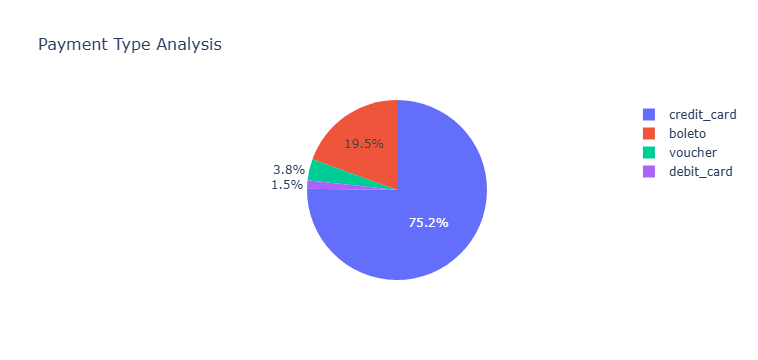

In [27]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Pie(
        labels=payment_type_count.index,
        values=payment_type_count.values
    )
)

fig.update_layout(
    {
        "title": {
            "text": "Payment Type Analysis",
            "font": {
                "size": 16
            }
        }
    }
)

fig.show()

# **4. 고객의 (월)평균 거래액은 얼마나 되는가 (향후 잠재 가능성 확인)**

In [28]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [29]:
# 평균 값을 낸다 > 데이터의 결측, 기준 날짜 등을 확인해야 함
# SQL : 
# 주문 정보 테이블 (주문 발생에 따른 식별값, 주문날짜, 승인날짜) 주문 금액 X
# 주문 상품 테이블 (주문발생에 따른 주문상품, 상품별 금액) 

# plotly 종류 확인할 수 있는 사이트

https://plotly.com/?source=graphing_libraries&medium=documentation&content=logo_python

In [30]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [31]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [33]:
# orders, order_items, payments

In [34]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [37]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [38]:
orders = orders.dropna()

In [39]:
orders.isnull().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

In [41]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
Index: 103883 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103883 non-null  object 
 1   payment_sequential    103883 non-null  int64  
 2   payment_type          103883 non-null  object 
 3   payment_installments  103883 non-null  int64  
 4   payment_value         103883 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.8+ MB


In [42]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96461 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       96461 non-null  object
 1   customer_id                    96461 non-null  object
 2   order_status                   96461 non-null  object
 3   order_purchase_timestamp       96461 non-null  object
 4   order_approved_at              96461 non-null  object
 5   order_delivered_carrier_date   96461 non-null  object
 6   order_delivered_customer_date  96461 non-null  object
 7   order_estimated_delivery_date  96461 non-null  object
dtypes: object(8)
memory usage: 6.6+ MB


In [43]:
# 1개의 행을 기준으로 동일한 값이 존재한다면, 해당 행의 갯수 집계 : value_counts().max()
# -> 동일한 값이 최대 몇번 반복 사용되는가!

In [45]:
orders["order_id"].value_counts().max()

1

In [46]:
payments["order_id"].value_counts().max()

29

In [47]:
payments["order_id"].value_counts()

order_id
fa65dad1b0e818e3ccc5cb0e39231352    29
ccf804e764ed5650cd8759557269dc13    26
285c2e15bebd4ac83635ccc563dc71f4    22
895ab968e7bb0d5659d16cd74cd1650c    21
fedcd9f7ccdc8cba3a18defedd1a5547    19
                                    ..
a7737f6d9208dd56ea498a322ed3c37f     1
646e62df54f3e236eb6d5ff3b31429b8     1
e115da7a49ec2acf622e1f31da65cfb9     1
f22592e01ddc0711e6794f900fa5e787     1
28bbae6599b09d39ca406b747b6632b1     1
Name: count, Length: 99437, dtype: int64

In [48]:
payments[payments["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
4885,fa65dad1b0e818e3ccc5cb0e39231352,27,voucher,1,66.02
9985,fa65dad1b0e818e3ccc5cb0e39231352,4,voucher,1,29.16
14321,fa65dad1b0e818e3ccc5cb0e39231352,1,voucher,1,3.71
17274,fa65dad1b0e818e3ccc5cb0e39231352,9,voucher,1,1.08
19565,fa65dad1b0e818e3ccc5cb0e39231352,10,voucher,1,12.86
23074,fa65dad1b0e818e3ccc5cb0e39231352,2,voucher,1,8.51
24879,fa65dad1b0e818e3ccc5cb0e39231352,25,voucher,1,3.68
28330,fa65dad1b0e818e3ccc5cb0e39231352,5,voucher,1,0.66
29648,fa65dad1b0e818e3ccc5cb0e39231352,6,voucher,1,5.02
32519,fa65dad1b0e818e3ccc5cb0e39231352,11,voucher,1,4.03


In [66]:
payments = payments.groupby("order_id", as_index=False).sum()
# payments[payments["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"]

In [67]:
dir(payments)

['T',
 '_AXIS_LEN',
 '_AXIS_ORDERS',
 '_AXIS_TO_AXIS_NUMBER',
 '_HANDLED_TYPES',
 '__abs__',
 '__add__',
 '__and__',
 '__annotations__',
 '__array__',
 '__array_priority__',
 '__array_ufunc__',
 '__arrow_c_stream__',
 '__bool__',
 '__class__',
 '__contains__',
 '__copy__',
 '__dataframe__',
 '__dataframe_consortium_standard__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dict__',
 '__dir__',
 '__divmod__',
 '__doc__',
 '__eq__',
 '__finalize__',
 '__firstlineno__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__imod__',
 '__imul__',
 '__init__',
 '__init_subclass__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lt__',
 '__matmul__',
 '__mod__',
 '__module__',
 '__mul__',
 '__ne__',
 '__neg__',
 '__new__',
 '__nonzero__',
 '__or__',
 '__pandas_priority__',
 '__pos__

In [68]:
pd.merge

<function pandas.core.reshape.merge.merge(left: 'DataFrame | Series', right: 'DataFrame | Series', how: 'MergeHow' = 'inner', on: 'IndexLabel | AnyArrayLike | None' = None, left_on: 'IndexLabel | AnyArrayLike | None' = None, right_on: 'IndexLabel | AnyArrayLike | None' = None, left_index: 'bool' = False, right_index: 'bool' = False, sort: 'bool' = False, suffixes: 'Suffixes' = ('_x', '_y'), copy: 'bool | None' = None, indicator: 'str | bool' = False, validate: 'str | None' = None) -> 'DataFrame'>

In [69]:
payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,credit_card,2,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,credit_card,3,259.83
2,000229ec398224ef6ca0657da4fc703e,1,credit_card,5,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,credit_card,2,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,credit_card,3,218.04
...,...,...,...,...,...
99435,fffc94f6ce00a00581880bf54a75a037,1,boleto,1,343.40
99436,fffcd46ef2263f404302a634eb57f7eb,1,boleto,1,386.53
99437,fffce4705a9662cd70adb13d4a31832d,1,credit_card,3,116.85
99438,fffe18544ffabc95dfada21779c9644f,1,credit_card,3,64.71


In [70]:
payments = pd.read_csv(f"{PATH}olist_order_payments_dataset.csv", encoding="utf-8-sig")

In [71]:
payments = payments.groupby("order_id", as_index=False).sum()

In [72]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,credit_card,2,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,credit_card,3,259.83
2,000229ec398224ef6ca0657da4fc703e,1,credit_card,5,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,credit_card,2,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,credit_card,3,218.04


In [73]:
payments.info() # orders 99440 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99440 entries, 0 to 99439
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   order_id              99440 non-null  object 
 1   payment_sequential    99440 non-null  int64  
 2   payment_type          99440 non-null  object 
 3   payment_installments  99440 non-null  int64  
 4   payment_value         99440 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 3.8+ MB


In [81]:
payments["order_id"].value_counts().max()

1

In [82]:
merged_order = pd.merge(orders, payments, on="order_id")

In [83]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [84]:
merged_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96460 entries, 0 to 96459
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       96460 non-null  object 
 1   customer_id                    96460 non-null  object 
 2   order_status                   96460 non-null  object 
 3   order_purchase_timestamp       96460 non-null  object 
 4   order_approved_at              96460 non-null  object 
 5   order_delivered_carrier_date   96460 non-null  object 
 6   order_delivered_customer_date  96460 non-null  object 
 7   order_estimated_delivery_date  96460 non-null  object 
 8   payment_sequential             96460 non-null  int64  
 9   payment_type                   96460 non-null  object 
 10  payment_installments           96460 non-null  int64  
 11  payment_value                  96460 non-null  float64
dtypes: float64(1), int64(2), object(9)
memory usag

In [78]:
# object (문자열 | 복수의 타입 혼합) -> 문자열 : 날짜타입 Datetime

In [86]:
df = pd.DataFrame({
    "order": [
        "2026-01-01 07:10:00",
        "2026-01-08 07:20:30",
        "2026-02-20 04:12:00",
        "2026-02-20 12:24:08",
        "2026-02-28 17:10:50",
        "2026-06-20 21:10:06",
        "2026-08-10 21:15:54",
    ]
})

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   order   7 non-null      object
dtypes: object(1)
memory usage: 188.0+ bytes


In [ ]:
# to_datetime() : 날짜와 시간을 나타내는 문자열 -> datetime 타입으로 변환 역할
# 어떤 형태의 날짜 데이터로 변환시키도록 할 것인가? >> 약속된 문법 사용이 필요!
# %y = 연도를 축약한 2자리 수
# %Y = 연도를 축약하지 않은 4자리 수
# %m = 월을 2자리수로 표기 (01 ~ 12)
# %d = 일을 2자리수로 표기 (01 ~31)
# %H = 24시간 기준으로 시간 표기 (00 ~ 23)
# %M = 분을 2자리수로 표기 (00 ~ 59)
# %S = 초 2자리수로 표기 (00 ~ 59)
# 옵션값 => 2026-10-21 09:05:63 => 날짜 가능 // errors = raise(기본) : 에러발생, 코드 실행 멈춤
# ignore : 변환 불가 값 > 건너뜀
# coerce : 변환 불가 값 > NaT 변환

In [88]:
df["order"] = pd.to_datetime(df["order"], format="%Y-%m-%d %H:%M:%S", errors="coerce")

In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   order   7 non-null      datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 188.0 bytes


In [100]:
merged_order["order_purchase_timestamp"] = pd.to_datetime(merged_order["order_purchase_timestamp"], format="%Y-%m-%d %H:%M:%S", errors="coerce")

In [101]:
merged_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96460 entries, 0 to 96459
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96460 non-null  object        
 1   customer_id                    96460 non-null  object        
 2   order_status                   96460 non-null  object        
 3   order_purchase_timestamp       96460 non-null  datetime64[ns]
 4   order_approved_at              96460 non-null  object        
 5   order_delivered_carrier_date   96460 non-null  object        
 6   order_delivered_customer_date  96460 non-null  object        
 7   order_estimated_delivery_date  96460 non-null  object        
 8   payment_sequential             96460 non-null  int64         
 9   payment_type                   96460 non-null  object        
 10  payment_installments           96460 non-null  int64         
 11  payment_value  

In [133]:
merged_order_payment_date = merged_order[["order_purchase_timestamp", "payment_value"]].copy()

In [134]:
merged_order_payment_date

,order_purchase_timestamp,payment_value
0,2017-10-02 10:56:33,38.71
1,2018-07-24 20:41:37,141.46
2,2018-08-08 08:38:49,179.12
3,2017-11-18 19:28:06,72.20
4,2018-02-13 21:18:39,28.62
...,...,...
96455,2017-03-09 09:54:05,85.08
96456,2018-02-06 12:58:58,195.00
96457,2017-08-27 14:46:43,271.01
96458,2018-01-08 21:28:27,441.16


In [135]:
merged_order_payment_date = merged_order_payment_date.set_index("order_purchase_timestamp")

In [136]:
merged_order_payment_date

,payment_value
order_purchase_timestamp,
2017-10-02 10:56:33,38.71
2018-07-24 20:41:37,141.46
2018-08-08 08:38:49,179.12
2017-11-18 19:28:06,72.20
2018-02-13 21:18:39,28.62
...,...
2017-03-09 09:54:05,85.08
2018-02-06 12:58:58,195.00
2017-08-27 14:46:43,271.01


In [137]:
# groupby : 특정 컬럼을 기준으로 동일한 값을 활용해서 나머지 요소를 집계하는 방식
# 이미 그룹화가 되어 있는 요소를 대상으로 한번 더 세부적인 요소로 재분류를 하고자 하는 경우
merged_order_payment_date = merged_order_payment_date.reset_index()

In [138]:
merged_order_month_sum = merged_order_payment_date.groupby(pd.Grouper(key="order_purchase_timestamp", freq="ME")).sum()
merged_order_month_sum.head()

,payment_value
order_purchase_timestamp,
2016-10-31,47271.20
2016-11-30,0.00
2016-12-31,19.62
2017-01-31,127430.74
2017-02-28,269458.98


In [ ]:
# 데이터프레임.groupby(pd.Grouper(key="그룹을 만들고 싶은 컬럼명", freq="세부기준 설정"))
# ME = Month end Frequency
# QE = Quarter end Frequency
# YE = Year end Frequency
# D = Calendar day Frequency
# h = Hourly Frequency
# min = Minutely Frequency
# s = Secondly Frequency

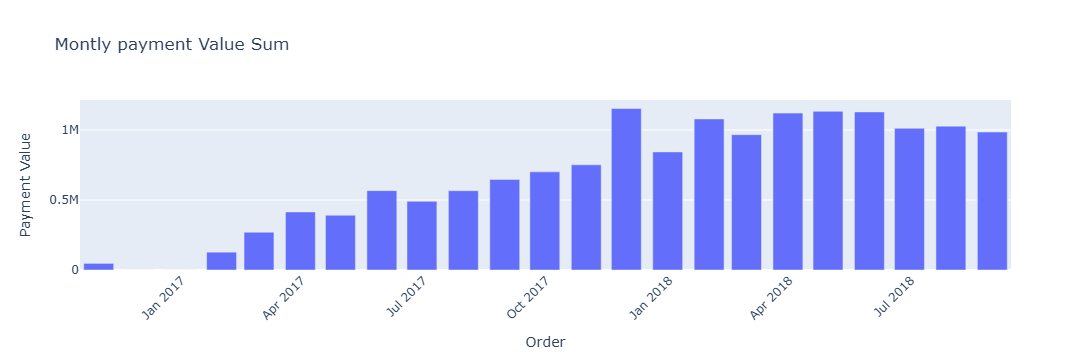

In [142]:
import plotly.express as px

fig = px.bar(
    x=merged_order_month_sum.index,
    y=merged_order_month_sum["payment_value"],
    title="Montly payment Value Sum",
    labels={
        "x": "Order",
        "y": "Payment Value"
    }
)

fig.update_layout(xaxis_tickangle=-45)


fig.show()

### **고객의 (월)평균 거래액 : R$670420.99 헤알** (누락월 포함)

### **고객의 (월)평균 거래액 : R$768619.6015 헤알** (누락월 미포함)

In [143]:
merged_order_month_sum["payment_value"].mean()

np.float64(670420.9934782608)

In [144]:
merged_order_month_sum.head()

,payment_value
order_purchase_timestamp,
2016-10-31,47271.20
2016-11-30,0.00
2016-12-31,19.62
2017-01-31,127430.74
2017-02-28,269458.98


In [147]:
merged_order_month_sum.iloc[:1]

,payment_value
order_purchase_timestamp,
2016-10-31,47271.2


In [149]:
merged_order_month_sum.iloc[3:]

,payment_value
order_purchase_timestamp,
2017-01-31,127430.74
2017-02-28,269458.98
2017-03-31,414369.39
2017-04-30,390952.18
2017-05-31,566872.73
2017-06-30,490225.60
2017-07-31,566403.93
2017-08-31,646000.61
2017-09-30,700976.01


In [ ]:
merged_order_month_sum = concat([
    merged_order_month_sum[:1],
    merged_order_month_sum.iloc[3:]
])

In [150]:
merged_order_month_sum.iloc[3:].mean()

payment_value    768619.6015
dtype: float64